In [ ]:
# ============================================
# الخلية 1: جلب البيانات الديناميكية (آخر 122 يوم حتى اليوم)
# ============================================
import pandas as pd
import requests
import json
from datetime import datetime, timedelta
from google.colab import files

print("🚀 بدء جلب البيانات الديناميكية...\n")

# 1. حساب التواريخ ديناميكياً
end_date = datetime.now()
start_date = end_date - timedelta(days=122)

start_str = start_date.strftime('%Y%m%d')
end_str = end_date.strftime('%Y%m%d')

print(f"📅 الفترة المطلوبة: من {start_str} إلى {end_str}")

# 2. إعداد طلب NASA POWER API
url = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {
    'parameters': 'T2M_MAX,T2M_MIN,RH2M,WS10M,T2M,GWETTOP,GWETROOT,PRECTOTCORR',
    'community': 'RE',
    'longitude': 35.39,
    'latitude': 32.2438,
    'start': start_str,
    'end': end_str,
    'format': 'JSON'
}

try:
    print("📡 جاري الاتصال بـ NASA POWER...")
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    data = response.json()

    # استخراج البيانات وتحويلها لجدول
    parameters = data['properties']['parameter']
    new_data = pd.DataFrame(parameters)
    new_data = new_data.reset_index()
    new_data = new_data.rename(columns={'index': 'DATE'})

    # تنسيق التاريخ وإضافة الأعمدة الأساسية
    new_data['DATE'] = pd.to_datetime(new_data['DATE'])
    new_data['SEQ'] = range(1, len(new_data) + 1)
    new_data['YEAR'] = new_data['DATE'].dt.year
    new_data['DOY'] = new_data['DATE'].dt.dayofyear

    print(f"✅ تم جلب {len(new_data)} يوم بنجاح!")

    # حفظ نسخة احتياطية خام
    with open('nasa_raw_data.json', 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    new_data.to_excel('nasa_raw_data.xlsx', index=False, engine='openpyxl')
    print("💾 تم حفظ البيانات الخام محلياً.")

except Exception as e:
    print(f"❌ فشل الاتصال: {e}")
    print("💡 ملاحظة: يمكنك رفع ملف Excel يدوياً في الخلية التالية إذا فشل الاتصال.")
    new_data = None

🚀 بدء جلب البيانات الديناميكية...

📅 الفترة المطلوبة: من 20260709 إلى 20261108
📡 جاري الاتصال بـ NASA POWER...
✅ تم جلب 123 يوم بنجاح!
💾 تم حفظ البيانات الخام محلياً.


In [ ]:
# ============================================
# خلية اختبار كاملة: جلب + حفظ + تحميل
# ============================================

import pandas as pd
import requests
import json
from google.colab import files
from datetime import datetime

print("🚀 بدء الاختبار...\n")

# ============================================
# الخطوة 1: جلب البيانات من NASA POWER
# ============================================
print("📡 1. جاري الاتصال بـ NASA POWER...")

url = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {
    'parameters': 'T2M_MAX,T2M_MIN,RH2M,WS10M,T2M,GWETTOP,GWETROOT,PRECTOTCORR',
    'community': 'RE',
    'longitude': 35.39,
    'latitude': 32.2438,
    'start': '20220901',
    'end': '20221231',
    'format': 'JSON'
}

try:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()  # يتحقق من نجاح الطلب
    data = response.json()

    # استخراج البيانات
    parameters = data['properties']['parameter']
    df = pd.DataFrame(parameters)
    df = df.reset_index()
    df = df.rename(columns={'index': 'DATE'})

    print(f"✅ تم جلب {len(df)} يوم بنجاح!")

except Exception as e:
    print(f"❌ فشل الاتصال: {e}")
    print("💡 الحل: تأكد من اتصال الإنترنت، أو استخدم ملف Excel الذي رفعته سابقاً")
    df = None

# ============================================
# الخطوة 2: الحفظ (فقط إذا نجح الجلب)
# ============================================
if df is not None and len(df) > 0:

    # حفظ JSON
    json_filename = 'nasa_raw_data.json'
    with open(json_filename, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print(f"\n💾 2. تم حفظ JSON: {json_filename}")

    # حفظ Excel
    excel_filename = 'nasa_raw_data.xlsx'
    df.to_excel(excel_filename, index=False, engine='openpyxl')
    print(f"💾 3. تم حفظ Excel: {excel_filename}")

    # ============================================
    # الخطوة 3: التحميل (فقط بعد التأكد من وجود الملفات)
    # ============================================
    import os

    if os.path.exists(json_filename):
        print(f"\n⬇️ 4. جاري تحميل {json_filename}...")
        files.download(json_filename)
    else:
        print(f"⚠️ ملف {json_filename} غير موجود!")

    if os.path.exists(excel_filename):
        print(f"⬇️ 5. جاري تحميل {excel_filename}...")
        files.download(excel_filename)
    else:
        print(f"⚠️ ملف {excel_filename} غير موجود!")

    # ============================================
    # الخطوة 4: عرض عينة من البيانات
    # ============================================
    print("\n" + "="*60)
    print("👀 عينة من البيانات (أول 5 صفوف):")
    print("="*60)
    display(df.head())

else:
    print("\n⚠️ لم يتم جلب البيانات - تخطي الحفظ والتحميل")

🚀 بدء الاختبار...

📡 1. جاري الاتصال بـ NASA POWER...
✅ تم جلب 122 يوم بنجاح!

💾 2. تم حفظ JSON: nasa_raw_data.json
💾 3. تم حفظ Excel: nasa_raw_data.xlsx

⬇️ 4. جاري تحميل nasa_raw_data.json...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ 5. جاري تحميل nasa_raw_data.xlsx...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


👀 عينة من البيانات (أول 5 صفوف):


,DATE,T2M_MAX,T2M_MIN,RH2M,WS10M,T2M,GWETTOP,GWETROOT,PRECTOTCORR
0,20220901,41.47,24.76,56.11,2.85,31.40,0.09,0.45,0.0
1,20220902,41.50,24.44,55.85,2.87,31.24,0.09,0.45,0.0
2,20220903,41.01,24.48,57.04,2.96,30.98,0.09,0.45,0.0
3,20220904,40.11,23.91,56.43,3.39,30.27,0.09,0.45,0.0
4,20220905,39.24,22.97,57.06,2.94,29.44,0.09,0.45,0.0


In [ ]:
# ============================================
# الخلية 2: رفع ملف قديم + تنظيف + تطبيق المعادلات
# ============================================

import pandas as pd
import numpy as np
from google.colab import files

print("📁 الرجاء رفع ملف Excel القديم:")
uploaded = files.upload()
old_filename = list(uploaded.keys())[0]

# محاولة قراءة الملف بذكاء (مع أو بدون skiprows)
try:
    # أولاً نحاول قراءة الملف مباشرة
    old_df = pd.read_excel(old_filename)
    old_df.columns = [str(col).strip() for col in old_df.columns]

    # إذا لم تكن الأعمدة الأساسية موجودة، قد يكون ملف CSV تاريخي يحتوي على 13 سطر وصفي، فنقوم بتخطيها
    if 'T2M_MAX' not in old_df.columns:
        old_df = pd.read_excel(old_filename, skiprows=13)
        old_df.columns = [str(col).strip() for col in old_df.columns]
except Exception as e:
    print(f"⚠️ حدث خطأ أثناء محاولة قراءة الملف: {e}")
    old_df = pd.read_excel(old_filename)

print(f"✅ تم قراءة {len(old_df)} صف من الملف القديم")

# ============================================
# دالة التنظيف الشاملة (تعمل على أي DataFrame)
# ============================================

def clean_and_engineer(df):
    """
    تنظف البيانات وتطبق جميع المعادلات
    تعمل على أي DataFrame يحتوي على أعمدة NASA
    """

    # 1. استبدال -999 بـ NaN (قيم مفقودة)
    df = df.replace(-999, np.nan)

    # 2. التأكد من أن الأعمدة الرقمية هي أرقام
    numeric_cols = ['T2M_MAX', 'T2M_MIN', 'RH2M', 'WS10M', 'T2M',
                    'GWETTOP', 'GWETROOT', 'PRECTOTCORR']
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # 3. إضافة عمود SEQ إذا غير موجود
    if 'SEQ' not in df.columns:
        df['SEQ'] = range(1, len(df) + 1)

    # ============================================
    # المعادلة 1: المدى الحراري اليومي
    # Excel: =T2M_MAX - T2M_MIN
    # ============================================
    df['Diurnal_Temp_Range'] = df['T2M_MAX'] - df['T2M_MIN']

    # ============================================
    # المعادلة 2: التحقق من المدى الحراري
    # Excel: =IF(Diurnal_Range > 0, "VALID", "INVALID")
    # ============================================
    df['Diurnal_Verification'] = np.where(
        df['Diurnal_Temp_Range'] > 0, 'VALID', 'INVALID'
    )

    # ============================================
    # المعادلة 3: المطر التراكمي
    # Excel: =SUM($J$2:J2)
    # ============================================
    df['Cumulative_Rainfall'] = df['PRECTOTCORR'].cumsum()

    # ============================================
    # المعادلة 4: التحقق من المطر
    # ============================================
    df['Rain_Verification'] = np.where(
        df['PRECTOTCORR'] >= 0, 'VALID', 'INVALID'
    )

    # ============================================
    # المعادلة 5: حالة رطوبة التربة (GWETROOT)
    # < 0.19 = Very dry
    # 0.19 - 0.46 = Ideal
    # >= 0.47 = Saturated
    # ============================================
    def get_soil_status(gwetroot):
        if pd.isna(gwetroot):
            return "Unknown"
        elif gwetroot < 0.19:
            return "Very dry"
        elif gwetroot < 0.47:
            return "Ideal for agriculture"
        else:
            return "Saturated"

    df['Soil_Status'] = df['GWETROOT'].apply(get_soil_status)

    # ============================================
    # المعادلة 6: التوصية الزراعية
    # ============================================
    def get_recommendation(row):
        tmax = row['T2M_MAX']
        rain = row['PRECTOTCORR']
        soil = row['Soil_Status']

        # استخراج الشهر
        if 'DATE' in row.index:
            try:
                date = pd.to_datetime(row['DATE'], format='%Y%m%d')
                month = date.month
            except:
                month = 11
        else:
            month = 11  # افتراضي

        # الشرط 1: تربة مشبعة
        if soil == "Saturated":
            return "🚫 التربة مشبعة - إيقاف الري فوراً"

        # الشرط 2: إجهاد حراري
        elif tmax > 35 and soil == "Very dry":
            return "⚠️ إجهاد حراري - تأجيل الزراعة وري طارئ"

        # الشرط 3: ظروف مثالية
        elif soil == "Ideal for agriculture":
            if month in [10, 11, 12, 1, 2]:
                return "✅ ظروف مثالية - ازرع البقوليات (فول/حمص/عدس)"
            else:
                return "🌱 ظروف جيدة - متابعة المحاصيل"

        # الشرط 4: جفاف
        else:
            return "⏳ انتظر - الظروف غير مناسبة"

    df['Recommendation'] = df.apply(get_recommendation, axis=1)

    # ============================================
    # المعادلة 7: توفير الأسمدة (%)
    # 35% إذا بقوليات + تربة مثالية
    # ============================================
    def get_fertilizer_savings(row):
        rec = str(row['Recommendation'])
        soil = row['Soil_Status']

        has_legumes = any(word in rec for word in ['بقوليات', 'فول', 'حمص', 'عدس'])

        if has_legumes and soil == 'Ideal for agriculture':
            return 0.35
        else:
            return 0.0

    df['Fertilizer_Savings_%'] = df.apply(get_fertilizer_savings, axis=1)

    print(f"✅ تم تطبيق {7} معادلات بنجاح!")
    return df

# ============================================
# تطبيق التنظيف على البيانات القديمة
# ============================================
clean_old_df = clean_and_engineer(old_df)

print(f"\n📊 الإحصائيات:")
print(f"   - أيام جافة جداً: {(clean_old_df['Soil_Status'] == 'Very dry').sum()}")
print(f"   - أيام مثالية: {(clean_old_df['Soil_Status'] == 'Ideal for agriculture').sum()}")
print(f"   - أيام مشبعة: {(clean_old_df['Soil_Status'] == 'Saturated').sum()}")
print(f"   - إجمالي الأمطار: {clean_old_df['Cumulative_Rainfall'].iloc[-1]:.2f} mm")

📁 الرجاء رفع ملف Excel القديم:


Saving nasa_raw_data (2).xlsx to nasa_raw_data (2).xlsx
✅ تم قراءة 122 صف من الملف القديم
✅ تم تطبيق 7 معادلات بنجاح!

📊 الإحصائيات:
   - أيام جافة جداً: 0
   - أيام مثالية: 76
   - أيام مشبعة: 46
   - إجمالي الأمطار: 52.75 mm


In [ ]:
# ============================================
# الخلية 3: دمج البيانات القديمة مع الجديدة
# ============================================

# تعريف متغير البيانات الجديدة محلياً لتجنب الأخطاء إذا لم تكن موجودة في الجلسة الحالية
try:
    new_data
except NameError:
    new_data = None

# إذا جلبت بيانات جديدة في الخلية 1
if new_data is not None:
    # تنظيف البيانات الجديدة بنفس المعادلات
    clean_new_df = clean_and_engineer(new_data)

    # دمج القديم والجديد
    merged_df = pd.concat([clean_old_df, clean_new_df], ignore_index=True)

    # توحيد صيغة عمود التاريخ لتفادي خطأ مقارنة النصوص والأرقام والتواريخ
    if 'DATE' in merged_df.columns:
        merged_df['DATE'] = pd.to_datetime(merged_df['DATE'], format='%Y%m%d', errors='coerce').combine_first(
            pd.to_datetime(merged_df['DATE'], errors='coerce')
        )

        # إزالة التكرار (إذا كان هناك تواريخ مكررة)
        merged_df = merged_df.drop_duplicates(subset=['DATE'], keep='last')
        merged_df = merged_df.sort_values('DATE').reset_index(drop=True)
        merged_df['SEQ'] = range(1, len(merged_df) + 1)

    print(f"✅ تم الدمج: {len(clean_old_df)} قديم + {len(clean_new_df)} جديد = {len(merged_df)} إجمالي")
else:
    merged_df = clean_old_df.copy()
    if 'DATE' in merged_df.columns:
        merged_df['DATE'] = pd.to_datetime(merged_df['DATE'], format='%Y%m%d', errors='coerce').combine_first(
            pd.to_datetime(merged_df['DATE'], errors='coerce')
        )
    print("⚠️ استخدام البيانات القديمة فقط")

# ============================================
# الترحيل: نقل التوقعات إلى التاريخي
# ============================================

print("\n🔄 عملية الترحيل (Rolling Update):")
print("="*50)

# محاكاة: نفترض أن آخر 7 أيام كانت "توقعات"
forecast_days = 7
last_date = merged_df['DATE'].max()

# التحقق من أن التاريخ صالح
if pd.notna(last_date):
    print(f"📅 آخر تاريخ في البيانات: {last_date.strftime('%Y-%m-%d')}")
    print(f"🔮 آخر {forecast_days} أيام كانت توقعات:")

    for i in range(forecast_days):
        date = last_date - timedelta(days=i)
        row = merged_df[merged_df['DATE'] == date]
        if not row.empty:
            print(f"   - {date.strftime('%Y-%m-%d')}: {row.iloc[0]['Soil_Status']}")

    print("\n✅ الآن هذه الأيام أصبحت 'تاريخية' في النظام")
    print("✅ يمكن توليد توقعات جديدة لـ 7 أيام قادمة")
else:
    print("⚠️ لم يتم العثور على تواريخ صالحة في عمود DATE لعملية الترحيل.")

✅ تم تطبيق 7 معادلات بنجاح!
✅ تم الدمج: 122 قديم + 123 جديد = 245 إجمالي

🔄 عملية الترحيل (Rolling Update):
📅 آخر تاريخ في البيانات: 2026-11-08
🔮 آخر 7 أيام كانت توقعات:
   - 2026-11-08: Unknown
   - 2026-11-07: Unknown
   - 2026-11-06: Unknown
   - 2026-11-05: Ideal for agriculture
   - 2026-11-04: Ideal for agriculture
   - 2026-11-03: Ideal for agriculture
   - 2026-11-02: Ideal for agriculture

✅ الآن هذه الأيام أصبحت 'تاريخية' في النظام
✅ يمكن توليد توقعات جديدة لـ 7 أيام قادمة


In [ ]:
# ============================================
# الخلية 4: التصدير إلى JSON و Excel
# ============================================

print("📤 بدء التصدير...")

# تجهيز البيانات للتصدير وتحويل التواريخ بشكل مناسب للـ JSON
export_df = merged_df.copy()
if 'DATE' in export_df.columns:
    export_df['DATE'] = export_df['DATE'].apply(lambda x: x.strftime('%Y-%m-%d') if pd.notna(x) else None)

# ============================================
# التصدير 1: JSON (للموقع)
# ============================================

json_data = {
    "metadata": {
        "location": "Al-Nasariya, Nablus, Palestine",
        "coordinates": {"latitude": 32.2438, "longitude": 35.39},
        "last_updated": datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        "source": "NASA POWER + Ofoq Framework",
        "total_days": len(export_df)
    },
    "daily_data": export_df.to_dict(orient='records')
}

# حفظ JSON
json_filename = 'ofoq_data.json'
with open(json_filename, 'w', encoding='utf-8') as f:
    json.dump(json_data, f, indent=2, ensure_ascii=False)

print(f"✅ تم حفظ JSON: {json_filename}")

# ============================================
# التصدير 2: Excel (للتقارير)
# ============================================

# لحفظ الـ Excel سنبقي على كائنات التواريخ الأصلية لسهولة تنسيقها في إكسل
excel_filename = 'ofoq_data.xlsx'
merged_df.to_excel(excel_filename, index=False, engine='openpyxl')

print(f"✅ تم حفظ Excel: {excel_filename}")

# ============================================
# تحميل الملفات إلى جهازك
# ============================================

print("\n⬇️ جاري تحميل الملفات...")
files.download(json_filename)
files.download(excel_filename)

print("\n🎉 اكتمل التصدير بنجاح!")
print(f"\n📊 ملخص البيانات:")
print(f"   - إجمالي الأيام: {len(merged_df)}")
if 'DATE' in merged_df.columns:
    print(f"   - الفترة: {merged_df['DATE'].min().strftime('%Y-%m-%d')} إلى {merged_df['DATE'].max().strftime('%Y-%m-%d')}")
print(f"   - إجمالي الأمطار: {merged_df['Cumulative_Rainfall'].iloc[-1]:.2f} mm")
print(f"   - متوسط الحرارة العظمى: {merged_df['T2M_MAX'].mean():.1f}°C")

📤 بدء التصدير...
✅ تم حفظ JSON: ofoq_data.json
✅ تم حفظ Excel: ofoq_data.xlsx

⬇️ جاري تحميل الملفات...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 اكتمل التصدير بنجاح!

📊 ملخص البيانات:
   - إجمالي الأيام: 245
   - الفترة: 2022-09-01 إلى 2026-11-08
   - إجمالي الأمطار: nan mm
   - متوسط الحرارة العظمى: 32.9°C


🔮 بدء توليد توقعات 7 أيام قادمة...

📊 نستخدم آخر 14 يوم كقاعدة للتنبؤ
   من 2026-10-26
   إلى 2026-11-08

📈 المؤشرات المحسوبة:
   - متوسط الحرارة العظمى: 28.6°C
   - متوسط المطر: 0.55 mm
   - متوسط رطوبة الجذور: 0.319
   - عامل الاتجاه الحراري: 1.03x

✅ تم توليد 7 يوم توقع بنجاح!

📋 جدول التوقعات للأسبوع القادم:


,DATE,T2M_MAX,T2M_MIN,PRECTOTCORR,GWETROOT,Soil_Status,Recommendation
0,2026-11-09,30.63,19.48,0.57,0.275,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
1,2026-11-10,30.45,19.37,0.57,0.276,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
2,2026-11-11,29.41,18.71,0.55,0.277,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
3,2026-11-12,28.91,18.39,0.54,0.278,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
4,2026-11-13,30.57,19.45,0.57,0.276,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
5,2026-11-14,30.45,19.37,0.57,0.276,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات
6,2026-11-15,28.56,18.17,0.53,0.279,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات


/tmp/ipykernel_1892/2250885625.py:141: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1892/2250885625.py:141: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


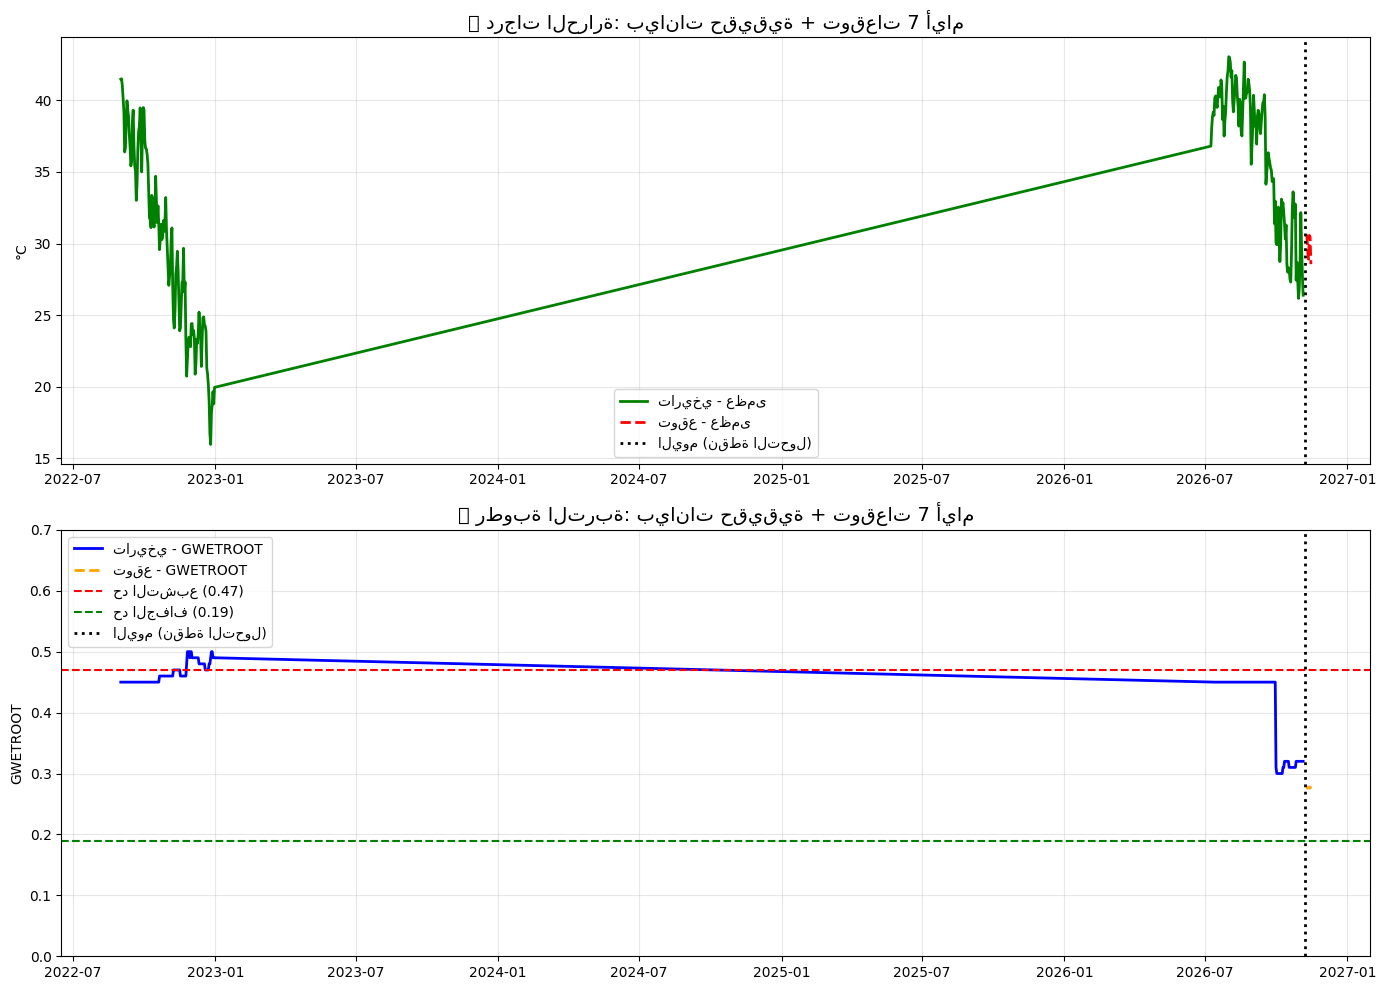


🎉 اكتمل النظام الديناميكي بنجاح! يمكنك الآن تصدير `full_df` في الخلية 4.


In [ ]:
# ============================================
# الخلية 5: التنبؤ بـ 7 أيام قادمة (بناءً على البيانات الحديثة)
# ============================================
import numpy as np
import matplotlib.pyplot as plt

print("🔮 بدء توليد توقعات 7 أيام قادمة...\n")

# التأكد من وجود بيانات
if 'merged_df' not in locals() or merged_df is None or len(merged_df) == 0:
    print("❌ لا توجد بيانات للتحليل. يرجى تشغيل الخلايا من 1 إلى 4 أولاً.")
else:
    # 1. أخذ آخر 14 يوم كقاعدة للتنبؤ
    last_14_days = merged_df.tail(14).copy()

    print(f"📊 نستخدم آخر {len(last_14_days)} يوم كقاعدة للتنبؤ")
    print(f"   من {last_14_days['DATE'].min().strftime('%Y-%m-%d')}")
    print(f"   إلى {last_14_days['DATE'].max().strftime('%Y-%m-%d')}")

    # 2. حساب المتوسطات والاتجاهات
    avg_tmax = last_14_days['T2M_MAX'].mean()
    avg_tmin = last_14_days['T2M_MIN'].mean()
    avg_rain = last_14_days['PRECTOTCORR'].mean()
    avg_gwetroot = last_14_days['GWETROOT'].mean()
    avg_gwettop = last_14_days['GWETTOP'].mean()
    avg_rh = last_14_days['RH2M'].mean()
    avg_wind = last_14_days['WS10M'].mean()

    # حساب عامل الاتجاه (Trend): هل الحرارة ترتفع أم تنخفض مقارنة بالأسبوع السابق؟
    recent_avg = last_14_days['T2M_MAX'].tail(7).mean()
    older_avg = last_14_days['T2M_MAX'].head(7).mean()
    trend_factor = recent_avg / older_avg if older_avg > 0 else 1.0

    print(f"\n📈 المؤشرات المحسوبة:")
    print(f"   - متوسط الحرارة العظمى: {avg_tmax:.1f}°C")
    print(f"   - متوسط المطر: {avg_rain:.2f} mm")
    print(f"   - متوسط رطوبة الجذور: {avg_gwetroot:.3f}")
    print(f"   - عامل الاتجاه الحراري: {trend_factor:.2f}x")

    # 3. توليد 7 أيام مستقبلية
    forecasts = []
    last_date = last_14_days['DATE'].max()
    last_seq = int(last_14_days['SEQ'].max())
    last_cum_rain = last_14_days['Cumulative_Rainfall'].iloc[-1]

    for day in range(1, 8):
        future_date = last_date + timedelta(days=day)

        # إضافة تباين عشوائي واقعي (±5%) لمحاكاة تقلبات الطقس
        noise = np.random.uniform(0.95, 1.05)

        forecast_tmax = round(avg_tmax * trend_factor * noise, 2)
        forecast_tmin = round(avg_tmin * trend_factor * noise, 2)
        forecast_rain = round(max(0, avg_rain * noise), 2)

        # معادلة مبسطة لتحديث رطوبة التربة: القديمة + مطر - تبخر (ET)
        et_daily = 0.0023 * ((forecast_tmax + forecast_tmin)/2 + 17.8) * np.sqrt(max(forecast_tmax - forecast_tmin, 1)) * 15
        forecast_gwetroot = round(max(0.10, min(0.60, avg_gwetroot + (forecast_rain/100) - (et_daily/100))), 3)
        forecast_gwettop = round(max(0.05, min(0.60, avg_gwettop + (forecast_rain/100) - (et_daily/80))), 3)

        last_cum_rain += forecast_rain

        # تصنيف حالة التربة المتوقعة
        if forecast_gwetroot >= 0.47:
            soil_status = "Saturated"
        elif forecast_gwetroot >= 0.19:
            soil_status = "Ideal for agriculture"
        else:
            soil_status = "Very dry"

        # توليد التوصية المتوقعة
        month = future_date.month
        if soil_status == "Saturated":
            rec = "🚫 التربة مشبعة - إيقاف الري فوراً"
        elif forecast_tmax > 35 and soil_status == "Very dry":
            rec = "⚠️ إجهاد حراري - تأجيل الزراعة"
        elif soil_status == "Ideal for agriculture":
            rec = "✅ ظروف مثالية - ازرع البقوليات" if month in [10, 11, 12, 1, 2] else "🌱 ظروف جيدة - متابعة المحاصيل"
        else:
            rec = "⏳ انتظر - الظروف غير مناسبة"

        forecasts.append({
            'SEQ': last_seq + day,
            'YEAR': future_date.year,
            'DATE': future_date,
            'DOY': future_date.timetuple().tm_yday,
            'T2M_MAX': forecast_tmax,
            'T2M_MIN': forecast_tmin,
            'RH2M': round(avg_rh * noise, 2),
            'WS10M': round(avg_wind * noise, 2),
            'T2M': round((forecast_tmax + forecast_tmin)/2, 2),
            'GWETTOP': forecast_gwettop,
            'GWETROOT': forecast_gwetroot,
            'PRECTOTCORR': forecast_rain,
            'Diurnal_Temp_Range': round(forecast_tmax - forecast_tmin, 2),
            'Diurnal_Verification': 'FORECAST',
            'Soil_Status': soil_status,
            'Rain_Verification': 'FORECAST',
            'Cumulative_Rainfall': round(last_cum_rain, 2),
            'Recommendation': rec,
            'Fertilizer_Savings_%': 0.35 if ('بقوليات' in rec and soil_status == 'Ideal for agriculture') else 0.0,
            'is_forecast': True  # علامة لتمييز البيانات المتوقعة
        })

    forecast_df = pd.DataFrame(forecasts)

    # 4. دمج البيانات التاريخية مع المتوقعة
    merged_df['is_forecast'] = False
    full_df = pd.concat([merged_df, forecast_df], ignore_index=True)

    print(f"\n✅ تم توليد {len(forecast_df)} يوم توقع بنجاح!")
    print("\n📋 جدول التوقعات للأسبوع القادم:")
    display(forecast_df[['DATE', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'GWETROOT', 'Soil_Status', 'Recommendation']])

    # 5. رسم بياني يوضح الانتقال من الواقع إلى التوقع
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    hist = full_df[full_df['is_forecast'] == False]
    fore = full_df[full_df['is_forecast'] == True]

    # شارت الحرارة
    axes[0].plot(hist['DATE'], hist['T2M_MAX'], 'g-', label='تاريخي - عظمى', linewidth=2)
    axes[0].plot(fore['DATE'], fore['T2M_MAX'], 'r--', label='توقع - عظمى', linewidth=2)
    axes[0].axvline(x=last_date, color='black', linestyle=':', linewidth=2, label='اليوم (نقطة التحول)')
    axes[0].set_title('🌡️ درجات الحرارة: بيانات حقيقية + توقعات 7 أيام', fontsize=14)
    axes[0].set_ylabel('°C')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # شارت رطوبة التربة
    axes[1].plot(hist['DATE'], hist['GWETROOT'], 'b-', label='تاريخي - GWETROOT', linewidth=2)
    axes[1].plot(fore['DATE'], fore['GWETROOT'], 'orange', linestyle='--', label='توقع - GWETROOT', linewidth=2)
    axes[1].axhline(y=0.47, color='red', linestyle='--', label='حد التشبع (0.47)')
    axes[1].axhline(y=0.19, color='green', linestyle='--', label='حد الجفاف (0.19)')
    axes[1].axvline(x=last_date, color='black', linestyle=':', linewidth=2, label='اليوم (نقطة التحول)')
    axes[1].set_title('💧 رطوبة التربة: بيانات حقيقية + توقعات 7 أيام', fontsize=14)
    axes[1].set_ylabel('GWETROOT')
    axes[1].set_ylim(0, 0.7)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n🎉 اكتمل النظام الديناميكي بنجاح! يمكنك الآن تصدير `full_df` في الخلية 4.")

In [ ]:
# ============================================
# الخلية الأخيرة: عرض البيانات النهائية في Colab
# ============================================
from IPython.display import display, HTML

print("📊 عرض البيانات النهائية (تاريخي + توقعات)")
print("="*70)

# 1. تحديد الأعمدة الأكثر أهمية للعرض لتجنب الازدحام في الشاشة
cols_to_show = [
    'SEQ', 'DATE', 'T2M_MAX', 'PRECTOTCORR',
    'GWETROOT', 'Soil_Status', 'Recommendation', 'is_forecast'
]

# التأكد من أن الأعمدة موجودة في الجدول قبل العرض
available_cols = [col for col in cols_to_show if col in full_df.columns]

# 2. عرض أول 5 صفوف (بيانات تاريخية حقيقية)
print("\n🔹 أول 5 أيام (بيانات تاريخية حقيقية):")
display(full_df[available_cols].head().style.set_properties(**{'text-align': 'center'}))

# 3. عرض آخر 7 صفوف (البيانات المتوقعة)
print("\n🔮 آخر 7 أيام (بيانات متوقعة - Forecast):")
forecast_view = full_df[full_df['is_forecast'] == True][available_cols]
display(forecast_view.style.set_properties(**{'text-align': 'center'}))

# 4. ملخص سريع للأرقام
print("\n" + "="*70)
print("📈 ملخص سريع للبيانات المعالجة:")
print(f"   ✅ إجمالي الأيام في الجدول: {len(full_df)} يوم")
print(f"   📅 أيام البيانات التاريخية: {(full_df['is_forecast'] == False).sum()} يوم")
print(f"   🔮 أيام التوقعات المستقبلية: {(full_df['is_forecast'] == True).sum()} أيام")
print(f"   💧 إجمالي الأمطار التراكمي: {full_df['Cumulative_Rainfall'].iloc[-1]:.2f} mm")
print(f"   🌱 أيام ظروف الزراعة المثالية: {(full_df['Soil_Status'] == 'Ideal for agriculture').sum()} يوم")
print("="*70)
print("\n💡 ملاحظة: لرؤية جميع الأعمدة الـ 20+ (بما فيها توفير الأسمدة وتصنيف الري)، يرجى فتح ملف 'ofoq_data.xlsx' الذي تم تحميله في الخلية السابقة.")

📊 عرض البيانات النهائية (تاريخي + توقعات)

🔹 أول 5 أيام (بيانات تاريخية حقيقية):


,SEQ,DATE,T2M_MAX,PRECTOTCORR,GWETROOT,Soil_Status,Recommendation,is_forecast
0,1,2022-09-01 00:00:00,41.470000,0.000000,0.450000,Ideal for agriculture,🌱 ظروف جيدة - متابعة المحاصيل,False
1,2,2022-09-02 00:00:00,41.500000,0.000000,0.450000,Ideal for agriculture,🌱 ظروف جيدة - متابعة المحاصيل,False
2,3,2022-09-03 00:00:00,41.010000,0.000000,0.450000,Ideal for agriculture,🌱 ظروف جيدة - متابعة المحاصيل,False
3,4,2022-09-04 00:00:00,40.110000,0.000000,0.450000,Ideal for agriculture,🌱 ظروف جيدة - متابعة المحاصيل,False
4,5,2022-09-05 00:00:00,39.240000,0.000000,0.450000,Ideal for agriculture,🌱 ظروف جيدة - متابعة المحاصيل,False



🔮 آخر 7 أيام (بيانات متوقعة - Forecast):


,SEQ,DATE,T2M_MAX,PRECTOTCORR,GWETROOT,Soil_Status,Recommendation,is_forecast
245,246,2026-11-09 00:00:00,30.630000,0.570000,0.275000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
246,247,2026-11-10 00:00:00,30.450000,0.570000,0.276000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
247,248,2026-11-11 00:00:00,29.410000,0.550000,0.277000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
248,249,2026-11-12 00:00:00,28.910000,0.540000,0.278000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
249,250,2026-11-13 00:00:00,30.570000,0.570000,0.276000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
250,251,2026-11-14 00:00:00,30.450000,0.570000,0.276000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True
251,252,2026-11-15 00:00:00,28.560000,0.530000,0.279000,Ideal for agriculture,✅ ظروف مثالية - ازرع البقوليات,True



📈 ملخص سريع للبيانات المعالجة:
   ✅ إجمالي الأيام في الجدول: 252 يوم
   📅 أيام البيانات التاريخية: 245 يوم
   🔮 أيام التوقعات المستقبلية: 7 أيام
   💧 إجمالي الأمطار التراكمي: nan mm
   🌱 أيام ظروف الزراعة المثالية: 203 يوم

💡 ملاحظة: لرؤية جميع الأعمدة الـ 20+ (بما فيها توفير الأسمدة وتصنيف الري)، يرجى فتح ملف 'ofoq_data.xlsx' الذي تم تحميله في الخلية السابقة.
